# Seminar 5. Stress and deformation of a plate with a circular hole

**Plane stress · linear triangular element · finite element method · Kirsch solution**

**Objective:** construct a finite element model of a quarter plate with a hole, determine displacements and stresses, and compare the stress distributions with the analytical Kirsch solution.

In the preceding heat-conduction seminars, each node had one unknown temperature. Here, the unknowns are **two displacement components**, $u_x$ and $u_y$. The finite element workflow remains the same: element interpolation → element matrix → global system → boundary conditions → solution → stress recovery.

**Analysis workflow:**

1. Prepare the geometry, mesh, and boundary groups in Gmsh.
2. Formulate the equations of plane elasticity and derive $\mathbf D$, $\mathbf B_e$, and $\mathbf K_e$.
3. Assemble $\mathbf K\mathbf U=\mathbf F$ and apply displacement constraints and external loads.
4. Obtain $u_x$, $u_y$, $\sigma_x$, $\sigma_y$, and $\tau_{xy}$.
5. Compute the polar stress components and compare them with the Kirsch solution.

All calculations use **SI units** (m, N, Pa). Unit conversions for plotting are stated separately. The notebook contains complete executable code.

## 1. Environment and input data

The notebook uses `numpy` for arrays and linear algebra, `matplotlib` for plotting, the `gmsh` Python API for geometry, meshing, and physical groups, and the standard-library modules `json` and `pathlib`.

**Reproducibility requires** the `gmsh` module and the input file `_geom/kirsch.xao`, which contains the plate geometry and named **Physical Groups**. Run the notebook from the project directory.

The notebook cannot be run from scratch without the input XAO file: the code alone does not reconstruct the geometry and physical groups. No CSV or JSON mesh files are imported in subsequent cells; data are extracted directly from the open Gmsh model.

In [1]:
## Dictionary serialization
import json
## Arrays and linear algebra
import numpy as np
## Visualization and plotting
import matplotlib.pyplot as plt
## Geometry and mesh generation
import gmsh
from pathlib import Path

In [2]:
# Prepared geometry with named boundary groups.
# Change the filename if the XAO file has a different name.
geo_file = Path("_geom") / "kirsch.xao"
# Output mesh for the finite element analysis.
mesh_path = Path("_geom") / "kirsch.msh"

## 2. Problem definition and geometry

Consider a homogeneous thin square plate with a central circular hole under tension in the $x$ direction. Symmetry of the geometry and loading allows us to model only a quarter of the domain:

$$
\Omega=\{(x,y):0\leq x\leq L,\;0\leq y\leq L,\; x^2+y^2\geq R^2\}.
$$

Here, $L=0.10$ m is the quarter-plate dimension along each coordinate axis, and $R=0.020$ m is the hole radius. The thickness $t$ is constant.

This is a **two-dimensional plane elasticity problem**, **not an axisymmetric problem**: the stiffness integrals do not contain a $2\pi r$ factor.

<p align="center">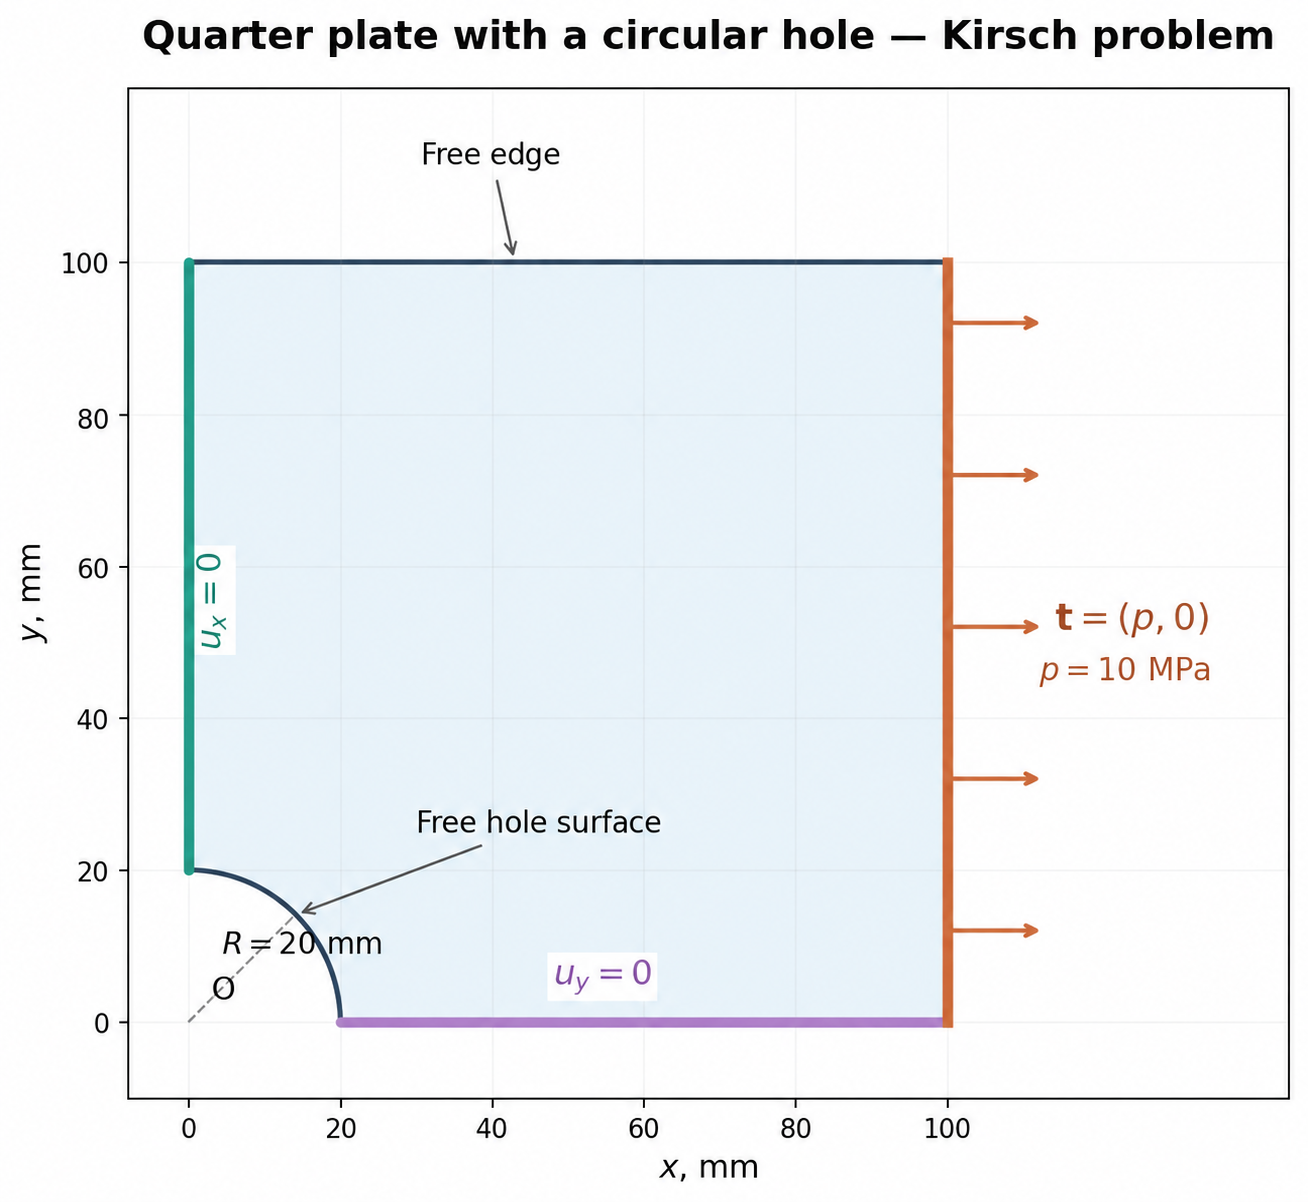</p>

<p align="center"><em>Figure 1. Quarter-plate model and mechanical boundary conditions.</em></p>

### 2.1. Mechanical boundary conditions

The quarter-plate boundary conditions are:

| Boundary | Condition | Physical meaning |
|---|---|---|
| Left vertical boundary $x=0$ (`SymX`) | $u_x=0$ | No displacement normal to the symmetry line; $u_y$ is unconstrained |
| Bottom horizontal boundary $y=0$ (`SymY`) | $u_y=0$ | No normal displacement; $u_x$ is unconstrained |
| Right boundary $x=L$ (`pressure`) | $\mathbf t=(p,0)$ | Uniform tensile traction in the positive $x$ direction |
| Top boundary $y=L$ | $\mathbf t=\mathbf 0$ | Traction-free surface |
| Hole boundary $r=R$ | $\mathbf t=\mathbf 0$ | Traction-free hole surface |

Here, $\mathbf t=\boldsymbol\sigma\mathbf n$ is the **traction vector** (Pa). Despite the group name `pressure` and the function name `bc_pressure`, the right boundary is subjected to a constant **Cartesian component of tensile traction**, not pressure on the hole boundary.

The parameters used below are:

| Symbol | Value | Code variable |
|---|---:|---|
| $L$ | 0.10 m | `L_domain` |
| $R$ | 0.020 m | `R_hole` (`R` in the analytical solution) |
| $p$ | 10 MPa | `p_load` |
| $E$ | 210 GPa | `E` |
| $\nu$ | 0.30 | `nu` |
| $t$ | 0.005 m | `th` |

### 2.2. Mesh generation

Gmsh opens the prepared geometry, generates linear triangular elements with a maximum target size of approximately 10 mm, and writes `kirsch.msh`. Physical Groups in the input geometry are needed to apply the loads and displacement constraints.

In [3]:
gmsh.initialize()
gmsh.open(str(geo_file))
# Generate the mesh and write it to a file
h = 0.01                                         # Maximum mesh size, m
gmsh.option.setNumber("Mesh.MeshSizeMax", h)
gmsh.option.setNumber("Mesh.ElementOrder", 1)
# Two-dimensional mesh for plane-stress elasticity
gmsh.model.mesh.generate(2)
mesh_path.parent.mkdir(parents=True, exist_ok=True)
gmsh.write(str(mesh_path))

Info    : Reading '_geom/kirsch.xao'...
Info    : Done reading '_geom/kirsch.xao'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 10%] Meshing curve 3 (Line)
Info    : [ 10%] Meshing curve 4 (Line)
Info    : [ 10%] Meshing curve 5 (Line)
Info    : [ 10%] Meshing curve 6 (Line)
Info    : [ 10%] Meshing curve 7 (Line)
Info    : [ 10%] Meshing curve 8 (Line)
Info    : [ 10%] Meshing curve 9 (Line)
Info    : [ 10%] Meshing curve 10 (Line)
Info    : [ 10%] Meshing curve 11 (Line)
Info    : [ 10%] Meshing curve 12 (Line)
Info    : [ 10%] Meshing curve 13 (Line)
Info    : [ 10%] Meshing curve 14 (Line)
Info    : [ 10%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 16 (Line)
Info    : [ 10%] Meshing curve 17 (Line)
Info    : [ 10%] Meshing curve 18 (Line)
Info    : [ 10%] Meshing curve 19 (Line)
Info    : [ 20%] Meshing curve 20 (Line)
Info    : [ 20%] Meshing curve 21 (Line)
Info    : [ 20%] Meshing curve 22 (Line)
I

In [4]:
# Read the generated mesh
gmsh.clear()
gmsh.open(str(mesh_path))

Info    : Clearing all models and views...
Info    : Done clearing all models and views
Info    : Reading '_geom/kirsch.msh'...
Info    : 369 entities
Info    : 760 nodes
Info    : 1338 elements
Info    : Done reading '_geom/kirsch.msh'


## 3. Mathematical model of plane elasticity

### 3.1. Displacement, strain, and equilibrium

The unknown functions are the displacement components:

$$
\mathbf u=\begin{bmatrix}u_x\\u_y\end{bmatrix},\qquad
\boldsymbol\varepsilon=\begin{bmatrix}\varepsilon_x\\\varepsilon_y\\\gamma_{xy}\end{bmatrix}
=\begin{bmatrix}
\partial u_x/\partial x\\
\partial u_y/\partial y\\
\partial u_x/\partial y+\partial u_y/\partial x
\end{bmatrix}.
$$

The third component is the **engineering shear strain**, $\gamma_{xy}=2\varepsilon_{xy}$.

In the absence of body forces, the differential equilibrium equations are

$$
\frac{\partial\sigma_x}{\partial x}+\frac{\partial\tau_{xy}}{\partial y}=0,\qquad
\frac{\partial\tau_{xy}}{\partial x}+\frac{\partial\sigma_y}{\partial y}=0.
$$

### 3.2. Plane stress

For a thin plate, assume $\sigma_z=\tau_{xz}=\tau_{yz}=0$. Hooke's law for an isotropic material is

$$
\boldsymbol\sigma=\mathbf D\boldsymbol\varepsilon,\qquad
\boldsymbol\sigma=\begin{bmatrix}\sigma_x\\\sigma_y\\\tau_{xy}\end{bmatrix},\qquad
\boxed{\mathbf D=\frac{E}{1-\nu^2}
\begin{bmatrix}1&\nu&0\\\nu&1&0\\0&0&(1-\nu)/2\end{bmatrix}}.
$$

The matrix $\mathbf D$ has dimensions $3\times3$ and units of Pa. A different constitutive matrix $\mathbf D$ would be required for **plane strain**.

### 3.3. Variational formulation

Consider a linear static problem without body forces or thermal strains. The total potential energy is

$$
\Pi(\mathbf u)=
\frac12\int_{\Omega} \boldsymbol\varepsilon^{\mathsf T}\mathbf D
\boldsymbol\varepsilon\,t\,dA
-\int_{\Gamma_t}\mathbf u^{\mathsf T}\mathbf t\,t\,d\Gamma.
$$

The first integral is the strain energy; the second is the negative of the work of the distributed external load. Finite element discretization and the stationarity condition $\delta\Pi=0$ give

$$
\Pi(\mathbf U)=\tfrac12\mathbf U^{\mathsf T}\mathbf K\mathbf U
-\mathbf U^{\mathsf T}\mathbf F,\qquad
\boxed{\mathbf K\mathbf U=\mathbf F}.
$$

For a mesh with $N$ nodes, the global vector contains $2N$ displacements, and $\mathbf K$ has dimensions $2N\times2N$.

**Connection to the preceding seminars:** the assembly principle is the same as in heat conduction, but each node now has two degrees of freedom instead of one.

## 4. Extracting the mesh and boundary groups

### 4.1. Preparing the Gmsh mesh

The preceding code cells open `_geom/kirsch.xao`, generate a **two-dimensional mesh of linear elements** with the specified maximum characteristic size `h=0.01` m, and write `_geom/kirsch.msh`. They then clear the current model and reopen the saved mesh.

### 4.2. Reading coordinates and connectivity

The following data are extracted directly from Gmsh:

- `pnts`: nodal coordinates, an array of shape `(nn, 2)`, **in meters**;
- `elms`: indices of the three vertices of each linear triangle, an array of shape `(ne, 3)`;
- `nn` and `ne`: the numbers of nodes and elements.

The code subtracts one from the Gmsh node tags in the connectivity array to obtain zero-based Python indices. It **assumes** that node tags are consecutive, start at 1, and correspond to the rows of `pnts`. This correspondence must be checked separately for an arbitrary Gmsh file. A prepared model is used here.

In [5]:
node_tags, pnts, _ = gmsh.model.mesh.getNodes()
pnts = pnts.reshape(-1, 3)                            
# Retain x and y for the two-dimensional problem
pnts = pnts[:, :2]

In [6]:
_, _, elms = gmsh.model.mesh.getElements(2)
elms = elms[0].reshape(-1, 3)
elms = elms - 1

In [7]:
# Store the numbers of nodes and elements for subsequent loops
nn = len(pnts)
ne = len(elms) 

### 4.3. Extracting physical groups and checking the mesh

For each one-dimensional physical group, `getNodesForPhysicalGroup()` returns the boundary nodes. Two helper algorithms then identify:

- `elements`: triangles with **exactly two** vertices in the selected group;
- `edges`: the corresponding pairs of boundary-edge vertices;
- `length`: the lengths of these edges in meters.

The resulting `boundary[group_name]` dictionary contains the keys `nodes`, `elements`, `edges`, and `length`. The names `SymX`, `SymY`, and `pressure` must be present in the input model because they are used to apply the boundary conditions.

**Limitation of the edge-extraction method:** the criterion "exactly two vertices in the group" is intended for this prepared triangular mesh. For arbitrary geometries and more complex boundary definitions, completeness and the absence of duplicate edges must be checked explicitly.

Use the following figure to check the mesh and group locations: `SymX` should lie on $x=0$, `SymY` on $y=0$, and `pressure` on $x=L$. The hole boundary must remain traction-free.

In [8]:
def sel_elms(elms, sel_nds):
    sel_elms = []
    for el in range(ne):
        n = np.isin(elms[el], sel_nds).sum()
        if n == 2:
            sel_elms.append(el)
    return np.array(sel_elms, dtype=int) 

In [9]:
def sel_edges(elms, sel_elms, sel_nds):
    edges = []
    for el in sel_elms:
        edge = elms[el][np.isin(elms[el], sel_nds)]
        edges.append(edge)
    return np.array(edges, dtype=int) 

In [10]:
boundary = {}
for dim, tag in gmsh.model.getPhysicalGroups(1):
    name  = gmsh.model.getPhysicalName(dim, tag)
    nodes, _ = gmsh.model.mesh.getNodesForPhysicalGroup(dim, tag)
    nodes = nodes - 1
    elements = sel_elms(elms, nodes)
    edges = sel_edges(elms, elements, nodes)
    
    L = []
    for nd1, nd2 in edges:
        L.append(np.linalg.norm(pnts[nd2] - pnts[nd1]))
    L = np.array(L)
    boundary[name] = {
            'nodes': np.asarray(nodes, dtype=np.int64),
            'elements': np.asarray(elements, dtype=np.int64),
            'edges': edges,
            'length': L
        }

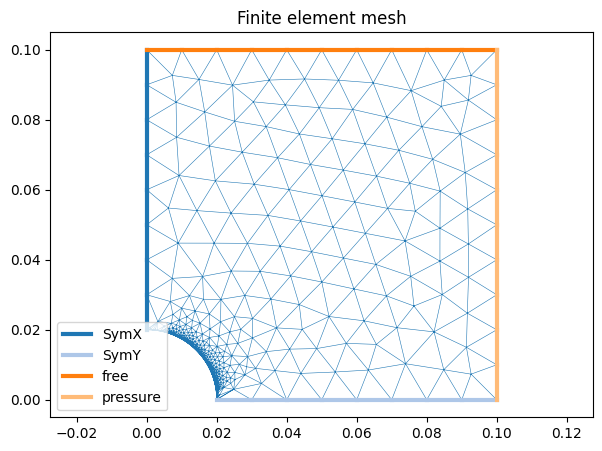

In [11]:
# Display all physical boundary groups
colors = plt.get_cmap("tab20").colors
# Create the figure
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Finite element mesh')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

## 5. Constant-strain triangle (CST)

### 5.1. Displacement interpolation

For a triangle with vertices $i,j,m$, the linear shape functions $N_i,N_j,N_m$ interpolate the displacement:

$$
\mathbf u(x,y)=\sum_{k\in\{i,j,m\}}N_k(x,y)
\begin{bmatrix}u_{x,k}\\u_{y,k}\end{bmatrix},\qquad
\mathbf U_e=\begin{bmatrix}u_{x,i}&u_{y,i}&u_{x,j}&u_{y,j}&u_{x,m}&u_{y,m}\end{bmatrix}^{\mathsf T}.
$$

The shape-function derivatives are constant in a linear triangle, so **strain and stress are constant within the element**.

### 5.2. Strain-displacement matrix

Let $A_e^{or}$ denote the signed triangle area:

$$
2A_e^{or}=(x_j-x_i)(y_m-y_i)-(y_j-y_i)(x_m-x_i),
\qquad A_e=|A_e^{or}|.
$$

Define $b_i=y_j-y_m$, $b_j=y_m-y_i$, $b_m=y_i-y_j$, and
$c_i=x_m-x_j$, $c_j=x_i-x_m$, $c_m=x_j-x_i$. Then

$$
\boldsymbol\varepsilon_e=\mathbf B_e\mathbf U_e,\qquad
\boxed{\mathbf B_e=\frac{1}{2A_e^{or}}
\begin{bmatrix}
b_i&0&b_j&0&b_m&0\\
0&c_i&0&c_j&0&c_m\\
c_i&b_i&c_j&b_j&c_m&b_m
\end{bmatrix}}.
$$

The **current `get_kel()` function** uses the positive area `area` in the denominator rather than the signed area. This is equivalent to the formula above **when all triangles have positive orientation** ($A_e^{or}>0$), as in the correctly oriented input mesh. If another mesh contains triangles with reversed vertex ordering, the recovered strains and stresses will have incorrect signs.

### 5.3. Element stiffness matrix

The matrix $\mathbf D$ depends on the material properties, while $\mathbf B_e$ depends on the vertex coordinates. For constant thickness and a homogeneous material,

$$
\boxed{\mathbf K_e= t A_e\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e},
\qquad [\mathbf K_e]=\text{N/m},
$$

where $\mathbf K_e$ has dimensions $6\times6$. The function `get_kel(element)` returns the **pair** `(Kel, B)`: `Kel` is used for assembly, and `B` for stress recovery.

In [12]:
# Input parameters (SI units)
L_domain = 0.10        # m
R_hole = 0.020         # m
p_load = 10e6          # Pa
E = 210e9              # Pa
nu = 0.30              # -
th = 0.005             # m

In [13]:
# Constitutive matrix for plane stress
D = E / (1 - nu**2) * np.array([
    [1,  nu, 0],
    [nu, 1,  0],
    [0,  0,  (1 - nu) / 2]])  

In [14]:
# Compute the element stiffness and strain-displacement matrices
def get_kel(element, th=th):
    i , j , m = element
    xi, yi = pnts[i]
    xj, yj = pnts[j]
    xm, ym = pnts[m]
    area = 0.5 * abs((xj-xi)*(ym-yi) - (yj-yi)*(xm-xi))
    # Strain-displacement matrix
    bi, bj, bm =  yj-ym, ym-yi, yi-yj
    ci, cj, cm =  xm-xj, xi-xm, xj-xi
    B = 1 / (2 *area) * np.array([
            [bi,  0,   bj,   0,   bm,   0 ],
            [0,   ci,  0,    cj,  0,    cm],
            [ci,  bi,  cj,   bj,  cm,   bm]])
    Kel = th  * area * B.T @ D @ B                                      # Use matrix multiplication, not elementwise multiplication
    return Kel, B   

### 5.4. Element checks

The stiffness matrix of a linear triangular element should be symmetric and have dimensions $6\times6$. A rigid-body translation produces zero strain; therefore, the row sums of $\mathbf K_e$ should be close to zero, allowing for round-off error.

The following cell prints the symmetry check, row sums, and entries of $\mathbf K_e$ for the first element.

In [15]:
Ke0, _ = get_kel(elms[0])
print('Symmetric:', np.allclose(Ke0, Ke0.T))
print('Row sums (should be close to zero):', Ke0.sum(axis=1))
print("Element stiffness matrix Ke (6 x 6):")
for row in Ke0:
    print(" ".join(f"{v:12.3e}" for v in row))

Symmetric: True
Row sums (should be close to zero): [ 1.99535862e-07 -1.25728548e-08 -9.68575478e-08 -2.08616257e-07
 -3.72529030e-08  1.49011612e-08]
Element stiffness matrix Ke (6 x 6):
   1.676e+09   -5.374e+08   -1.252e+09    5.391e+08   -4.247e+08   -1.678e+06
  -5.374e+08    9.817e+08    5.679e+08   -9.827e+08   -3.052e+07    1.009e+06
  -1.252e+09    5.679e+08    1.004e+09   -5.047e+08    2.476e+08   -6.326e+07
   5.391e+08   -9.827e+08   -5.047e+08    1.102e+09   -3.441e+07   -1.197e+08
  -4.247e+08   -3.052e+07    2.476e+08   -3.441e+07    1.771e+08    6.493e+07
  -1.678e+06    1.009e+06   -6.326e+07   -1.197e+08    6.493e+07    1.187e+08


## 6. Global system assembly

For $N=\texttt{nn}$ nodes, define a displacement vector with interleaved components:

$$
\mathbf U=\begin{bmatrix}u_{x,0}&u_{y,0}&u_{x,1}&u_{y,1}&\ldots\end{bmatrix}^{\mathsf T}.
$$

The global degree-of-freedom indices of element $e=(i,j,m)$ are

```python
IndX = [2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1]
```

Each $\mathbf K_e$ is added to the corresponding block of the global matrix:

$$\mathbf K[\mathrm{IndX},\mathrm{IndX}]\mathrel{+}=\mathbf K_e.$$

In **this implementation**, `Kglob` and `Fglob` are initialized as **dense** NumPy arrays (`np.zeros`), and blocks are selected using `np.ix_`. This is convenient for an instructional mesh, but requires more memory than sparse storage for large numbers of nodes. The initial vector $\mathbf F$ is zero; the external load is added later.

After assembly, `plt.spy(Kglob)` displays the nonzero structure of the global matrix, showing the coupling between element degrees of freedom.

In [16]:
Kglob  = np.zeros([2*nn, 2*nn])
Fglob = np.zeros(2*nn)

In [17]:
# Use np.ix_ to select the element block in the global matrix
for el in range(ne):
    # Each node has two consecutive displacement degrees of freedom
    i, j, m =elms[el]
    # Indices of the six element degrees of freedom
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # Indices must be integers
    # Assemble the element contribution into the global matrix
    IndXArr = np.ix_(IndX, IndX)
    Kel, _ = get_kel(elms[el])
    Kglob[IndXArr] += Kel    

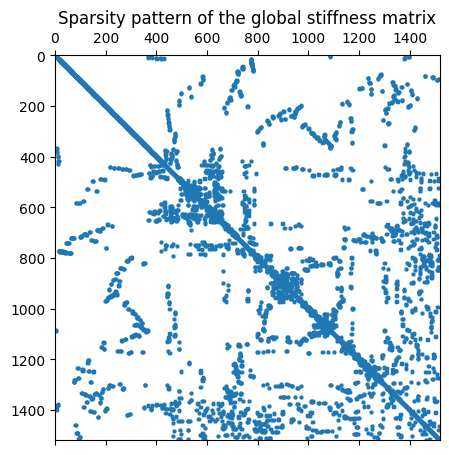

In [18]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Sparsity pattern of the global stiffness matrix')
plt.show()

## 7. Boundary conditions

### 7.1. Essential boundary conditions: displacements on symmetry lines

Impose $u_x=0$ on the vertical line $x=0$ and $u_y=0$ on the horizontal line $y=0$. Constraining both components on each line would overconstrain the model.

The function `bc_disp(K, F, boundary, ux, uy)` uses **equation replacement** for constrained degrees of freedom: the corresponding matrix row is zeroed, the diagonal entry is set to one, and the right-hand side is set to the prescribed displacement. An unspecified component is skipped using `np.nan`.

$$
K_{q,:}=0,\qquad K_{q,q}=1,\qquad F_q=\overline u_q.
$$

**Important:** the current code zeros **only rows**, retaining the columns. Consequently, after applying the constraints, `K1` is generally **nonsymmetric**, although the original `Kglob` is symmetric.

In [19]:
def bc_disp(K, F, boundary, ux=np.nan, uy=np.nan):
    for nd in boundary['nodes']:
        # Prescribe the x-displacement
        if not np.isnan(ux):
            idx = 2*nd
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = ux
        # Prescribe the y-displacement
        if not np.isnan(uy):
            idx = 2 * nd + 1
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = uy
    return K, F

### 7.2. Natural boundary conditions: distributed load

The right boundary is subjected to the traction vector $\mathbf t=(p,0)^{\mathsf T}$ in Pa. For an edge $(i,j)$ of length $\ell$, the equivalent nodal force vector follows from virtual work:

$$
\mathbf F_{\Gamma,e}=
 t\int_{\Gamma_e}\mathbf N^{\mathsf T}\mathbf t\,d\Gamma
 =\boxed{\frac{t\ell}{2}
\begin{bmatrix}p_x\\p_y\\p_x\\p_y\end{bmatrix}}.
$$

Each vertex receives half the total force on the edge. The units are consistent: $\mathrm{Pa}\cdot\mathrm{m}\cdot\mathrm{m}=\mathrm{N}$.

The function `bc_pressure()` iterates over `boundary['edges']` and `boundary['length']`, adding this vector to the **right-hand side**. The stiffness matrix is unchanged. No force vector needs to be added for the traction-free top and hole boundaries.

**Why is the edge normal not calculated here?** In this seminar, the load is specified in global coordinates: $p_x=p$, $p_y=0$ on the vertical right boundary. The prescribed **traction vector** can therefore be integrated directly. For normal pressure on an arbitrary boundary, the outward normal would have to be computed for each edge to convert the scalar pressure into load-vector components; `bc_pressure()` does not perform this conversion.

In [20]:
def bc_pressure(F, boundary, px=0, py=0, th=th):
    edges = boundary['edges']
    L = boundary['length']
    for (i, j), length in zip(edges, L):
        IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1], dtype=int)
        F[IndX] += th * length / 2 * np.array([px, py, px, py])
    return F 

### 7.3. Applying the boundary conditions and solving the linear system

The following cells perform these steps:

1. Copy the assembled `Kglob` and `Fglob`.
2. Call `bc_disp()` for `SymX` **with `ux=0`** and for `SymY` **with `uy=0`**.
3. Apply the tensile load using `bc_pressure(..., boundary['pressure'], px=p_load)`.
4. Solve $\mathbf K_1\mathbf U=\mathbf F_1$ using `np.linalg.solve`.

The computed `Disp` is a vector of length $2\,\texttt{nn}$, in **meters**. The array `Disp2plot = Disp.reshape(-1, 2).T`, with shape `(2, nn)`, contains $u_x$ in its first row and $u_y$ in its second.

In [21]:
K1 = Kglob.copy()
F1 = Fglob.copy()

In [22]:
## Symmetry boundary conditions
# Boundary x = 0: ux = 0
K1, F1 = bc_disp(K1, F1, boundary["SymX"], ux=0)
# Boundary y = 0: uy = 0
K1, F1 = bc_disp(K1, F1, boundary["SymY"], uy=0)

In [23]:
## Prescribed traction boundary condition
# Apply a tensile traction of 10 MPa to the right boundary
F1 = bc_pressure(F1, boundary["pressure"], px=p_load, py=0, th=th)

In [24]:
Disp = np.linalg.solve(K1, F1)
# Reshape the displacement vector into a 2 x nn array
Disp2plot = Disp.reshape(-1, 2).T

## 8. Displacement fields

After solving the global system, `Disp2plot` contains two rows of displacement components. Extract $u_x$, $u_y$, and the displacement magnitude:

$$u=\sqrt{u_x^2+u_y^2}.$$

All three quantities are **calculated and plotted in meters**.

In [25]:
## Visualize the results

In [26]:
# Displacement components and magnitude
Ux = Disp2plot[0, :]
Uy = Disp2plot[1, :]
U  = np.sqrt(Ux**2 + Uy**2)

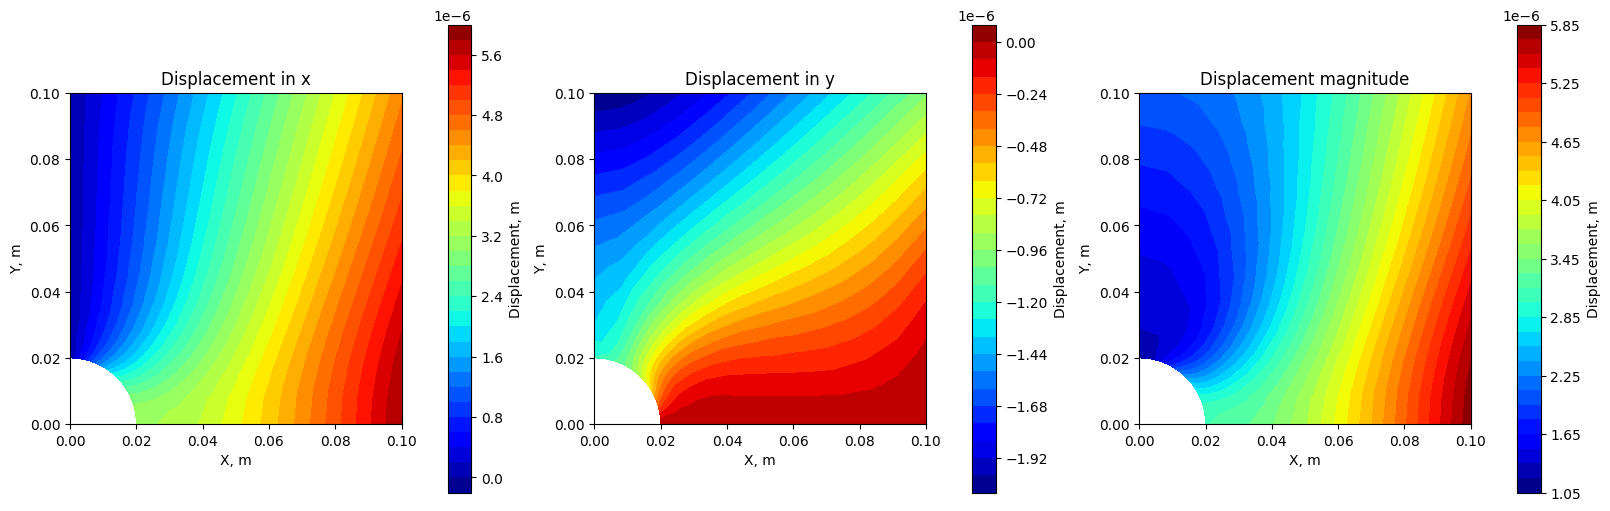

In [27]:
fields = [
    (Ux, "Displacement in x"),
    (Uy, "Displacement in y"),
    (U, "Displacement magnitude")
]

fig, axs = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

for ax, (values, title) in zip(axs, fields):
    im = ax.tricontourf(
        pnts[:, 0], pnts[:, 1],
        elms, values,
        levels=30, cmap='jet'
    )

    fig.colorbar(im, ax=ax, label='Displacement, m')
    ax.set_aspect('equal')
    ax.set_xlabel('X, m')
    ax.set_ylabel('Y, m')
    ax.set_title(title)

plt.show()

## 9. Stress recovery

### 9.1. Element strains and stresses

The global system provides **nodal displacements**. Stresses are then calculated for each element from its six degrees of freedom:

$$
\boldsymbol\varepsilon_e=\mathbf B_e\mathbf U_e,\qquad
\boxed{\boldsymbol\sigma_e=\mathbf D\mathbf B_e\mathbf U_e}.
$$

Here, `_, B = get_kel(elms[el])` retrieves $\mathbf B_e$ again and discards the stiffness matrix. The array `Sigma` has shape `(ne, 3)`; its columns contain $\sigma_x$, $\sigma_y$, and $\tau_{xy}$ **in Pa**.

For a constant-strain triangle (CST), strain and stress are **constant within each triangle**. These elementwise values can be discontinuous across an edge shared by adjacent elements. Nodal averaging is therefore used below to produce a smooth contour plot.

In [28]:
# Element stresses
Sigma = np.zeros((ne, 3))

for el in range(ne):
    i, j, m = elms[el]

    # Strain-displacement matrix
    _, B = get_kel(elms[el])

    # Element nodal displacements
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1],  dtype=int)
    Uel = Disp[IndX]

    # Strains and stresses
    Eps = B @ Uel
    Sigma[el] = D @ Eps

### 9.2. Nodal averaging for visualization

To produce a visually continuous contour plot, the code averages the stresses of the elements adjacent to each node:

$$
\overline{\boldsymbol\sigma}_i
=\frac{1}{n_i}\sum_{e\,\ni\,i}\boldsymbol\sigma_e,
$$

Here, $n_i$ is the number of triangles containing node $i$. The counter is `count`, and the results are `SX`, `SY`, and `SXY`, representing $\overline\sigma_x$, $\overline\sigma_y$, and $\overline\tau_{xy}$, respectively. This is **arithmetic averaging without area weighting**: it is intended for post-processing and smooths extrema near the hole. It does **not** enter the solution of the linear system.

In [29]:
# Accumulate stresses at the nodes
sigmaX_sum = np.zeros(nn)
sigmaY_sum = np.zeros(nn)
sigmaXY_sum = np.zeros(nn)
count = np.zeros(nn)

for el in range(ne):
    nodes = elms[el]

    sigmaX_sum[nodes] += Sigma[el, 0]
    sigmaY_sum[nodes] += Sigma[el, 1]
    sigmaXY_sum[nodes] += Sigma[el, 2]
    count[nodes] += 1

# Average the nodal stresses
SX = sigmaX_sum / count
SY = sigmaY_sum / count
SXY = sigmaXY_sum / count

### 9.3. Nodal Cartesian stress contours

The arrays `SX`, `SY`, and `SXY` contain $\overline\sigma_x$, $\overline\sigma_y$, and $\overline\tau_{xy}$, respectively, **in Pa**. For plotting, stresses are converted to MPa by dividing by $10^6$. Coordinates are in meters.

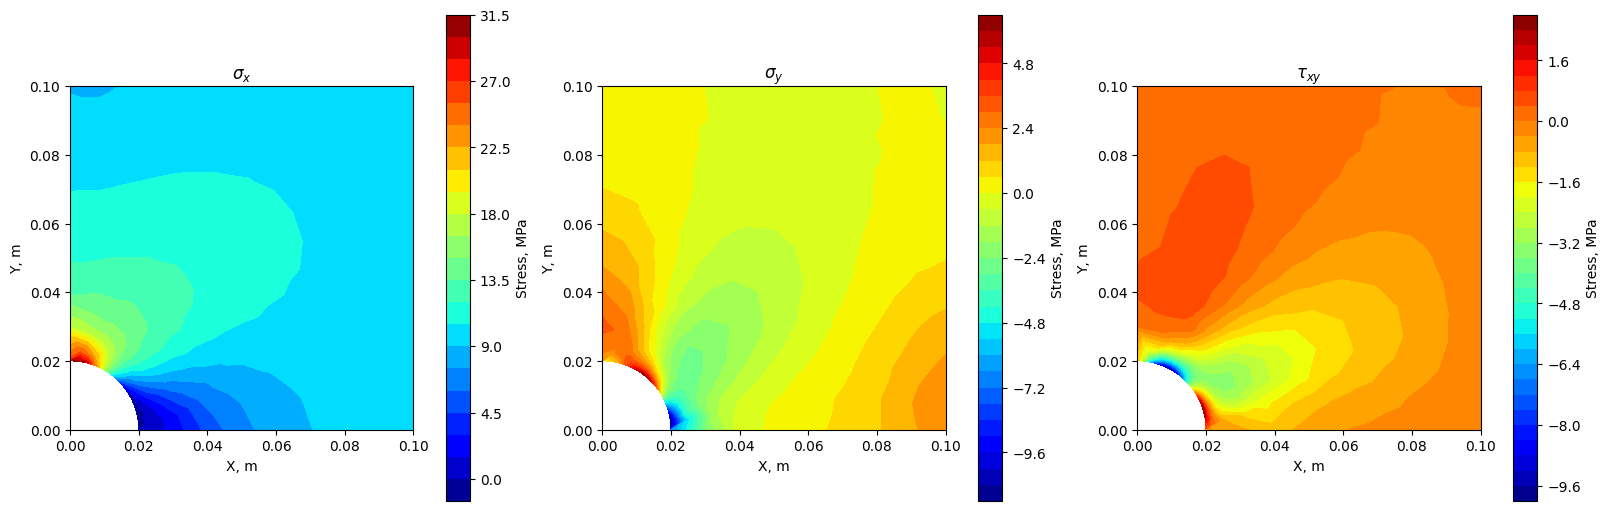

In [30]:
fields = [
    (SX,  r"$\sigma_x$"),
    (SY,  r"$\sigma_y$"),
    (SXY, r"$\tau_{xy}$")
]

fig, axs = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)

for ax, (values, title) in zip(axs, fields):
    im = ax.tricontourf(
        pnts[:, 0], pnts[:, 1],
        elms, values / 1e6,
        levels=30, cmap='jet'
    )

    fig.colorbar(im, ax=ax, label='Stress, MPa')
    ax.set_aspect('equal')
    ax.set_xlabel('X, m')
    ax.set_ylabel('Y, m')
    ax.set_title(title)

plt.show()

Add the nodal displacements to display the deformed model.

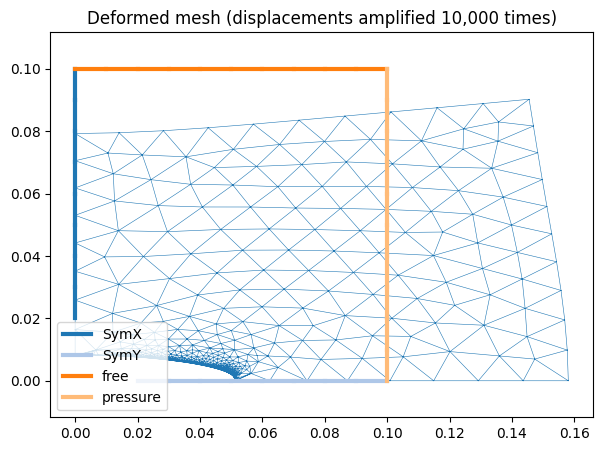

In [31]:
# Display all physical boundary groups
colors = plt.get_cmap("tab20").colors
# Create the figure
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Deformed mesh (displacements amplified 10,000 times)')
ax.triplot(pnts[:, 0]+Ux*10e3, pnts[:, 1]+Uy*10e3  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

## 10. Polar stresses and comparison with the Kirsch solution

For a circular hole, the radial and circumferential stresses are particularly informative. At the traction-free hole boundary, the exact solution satisfies $\sigma_{rr}=0$ and $\tau_{r\theta}=0$; the circumferential stress $\sigma_{\theta\theta}$ governs the stress concentration.

### 10.1. Nodal polar coordinates

For each **nodal** point $(x_i,y_i)$, compute its polar coordinates relative to the hole center $(0,0)$:

$$
r_i=\sqrt{x_i^2+y_i^2},\qquad \theta_i=\operatorname{atan2}(y_i,x_i).
$$

The arrays `r` and `theta` have length `nn`. These coordinates are used both to evaluate the analytical Kirsch stresses and to transform the finite element stresses. Because the domain contains a hole of radius $R>0$, a valid mesh has no nodes at $r=0$, so division by $r$ is well defined.

In [32]:
# Polar coordinates of the nodes
x, y = pnts[:, 0], pnts[:, 1]

r = np.sqrt(x**2 + y**2)
theta = np.arctan2(y, x)

### 10.2. Analytical Kirsch solution

For an **infinite** elastic plate with a traction-free circular hole of radius $R$, subjected to uniform remote tension $p$ in the $x$ direction, the stresses in polar coordinates are

$$
\boxed{\sigma_{rr}^{K}=
\frac p2\left[1-\frac{R^2}{r^2}+
\left(1-4\frac{R^2}{r^2}+3\frac{R^4}{r^4}\right)\cos(2\theta)\right]},
$$

$$
\boxed{\sigma_{\theta\theta}^{K}=
\frac p2\left[1+\frac{R^2}{r^2}-
\left(1+3\frac{R^4}{r^4}\right)\cos(2\theta)\right]},
$$

$$
\boxed{\tau_{r\theta}^{K}=
-\frac p2\left[1+2\frac{R^2}{r^2}-3\frac{R^4}{r^4}\right]\sin(2\theta)}.
$$

At $r=R$, $\sigma_{rr}^{K}=0$ and $\tau_{r\theta}^{K}=0$, while

$$
\sigma_{\theta\theta}^{K}(R,\theta)=p\bigl(1-2\cos(2\theta)\bigr).
$$

Thus, at $\theta=90^\circ$,

$$
\boxed{\sigma_{\theta\theta,\max}^{K}=3p=30\,\text{MPa}},
\qquad \boxed{K_t^{K}=\sigma_{\max}^{K}/p=3}.
$$

**Fundamental limitation of the comparison.** The Kirsch solution describes an infinite domain, whereas the finite element model represents a finite quarter plate ($L/R=5$) with uniform tensile traction applied only to the right boundary and a traction-free top boundary. In general, the Kirsch stresses on the outer boundary **do not satisfy** these boundary conditions. The numerical and analytical fields therefore need not agree exactly, even with an ideal mesh. The value 30 MPa is the **infinite-plate reference**, not a guaranteed result for the finite domain used here.

The following cell evaluates the theoretical components `sigma_rr_K`, `sigma_tt_K`, and `sigma_rt_K` **at the finite element nodes**, in Pa.

In [33]:
# Parameters for the Kirsch solution
R = 0.02       # Hole radius, m
p = p_load     # Tensile traction, Pa

# Analytical stresses
sigma_rr_K = p/2 * (
    1 - (R/r)**2 +
    (1 - 4*(R/r)**2 + 3*(R/r)**4)*np.cos(2*theta)
)

sigma_tt_K = p/2 * (
    1 + (R/r)**2 -
    (1 + 3*(R/r)**4)*np.cos(2*theta)
)

sigma_rt_K = -p/2 * (
    1 + 2*(R/r)**2 - 3*(R/r)**4
)*np.sin(2*theta)


### 10.3. Transforming nodal finite element stresses

After averaging, the stresses are available in Cartesian coordinates as `SX`, `SY`, and `SXY`. To compare them with the Kirsch solution, transform the stress tensor through the angle $\theta$:

$$
\boldsymbol\sigma_{polar}=\mathbf Q^{\mathsf T}\boldsymbol\sigma_{cart}\mathbf Q,\qquad
\mathbf Q=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}.
$$

In component form,

$$
\begin{aligned}
\sigma_{rr}&=\sigma_x\cos^2\theta+\sigma_y\sin^2\theta
+2\tau_{xy}\sin\theta\cos\theta,\\[3pt]
\sigma_{\theta\theta}&=\sigma_x\sin^2\theta+\sigma_y\cos^2\theta
-2\tau_{xy}\sin\theta\cos\theta,\\[3pt]
\tau_{r\theta}&=(\sigma_y-\sigma_x)\sin\theta\cos\theta
+\tau_{xy}(\cos^2\theta-\sin^2\theta).
\end{aligned}
$$

In **this notebook**, the transformation is performed **at the nodes**, not at the triangle centroids: `SX`, `SY`, `SXY`, and `theta` all have length `nn`. The Cartesian stress components are averaged first; the tensor is then transformed using the nodal coordinates. The resulting arrays are `sigma_rr`, `sigma_tt`, and `sigma_rt`, in Pa.

First compute $\cos\theta$ and $\sin\theta$ at all nodes, then apply the formulas above. The transformation to polar coordinates is used **for interpretation and comparison**, not to solve the global linear system: the finite element analysis itself is performed in Cartesian coordinates.

In [34]:
c = np.cos(theta)
s = np.sin(theta)

# Polar stress components (FEM)
sigma_rr = SX*c**2 + SY*s**2 + 2*SXY*s*c

sigma_tt = SX*s**2 + SY*c**2 - 2*SXY*s*c

sigma_rt = (SY-SX)*s*c + SXY*(c**2-s**2)


### 10.4. Comparison using common color scales

Two contour plots are produced for each of the three polar stress components: the finite element field on the left and the analytical Kirsch field on the right. Color-scale limits are shared **within each pair**, and stresses are converted from Pa to MPa by dividing by $10^6$. This is a visual comparison of **nodal** values, not a verification that the complete boundary-value problems are identical.

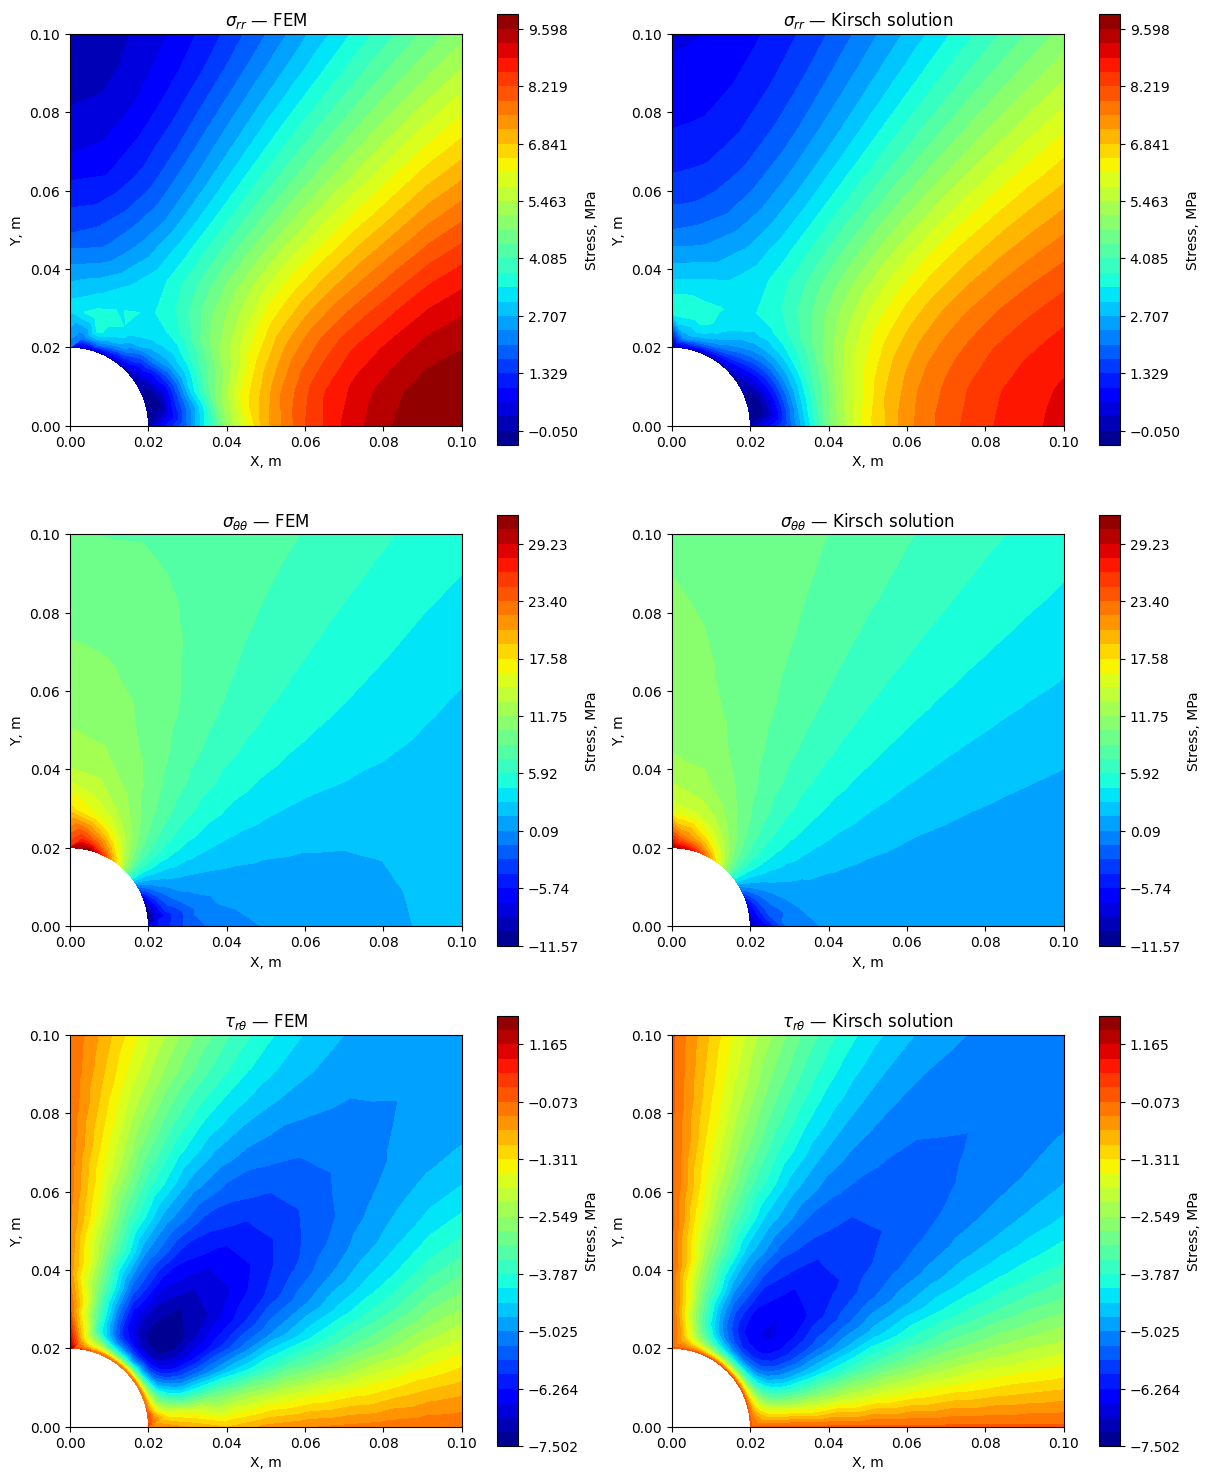

In [35]:

fields = [
    (sigma_rr, sigma_rr_K, r'$\sigma_{rr}$'),
    (sigma_tt, sigma_tt_K, r'$\sigma_{\theta\theta}$'),
    (sigma_rt, sigma_rt_K, r'$\tau_{r\theta}$')
]

fig, axs = plt.subplots(3, 2, figsize=(12, 15),
                        constrained_layout=True)

for row, (fem, theory, name) in enumerate(fields):

    # Use the same color scale for the FEM and analytical fields
    vmin = min(fem.min(), theory.min()) / 1e6
    vmax = max(fem.max(), theory.max()) / 1e6
    levels = np.linspace(vmin, vmax, 31)

    for col, (values, method) in enumerate([
        (fem, 'FEM'),
        (theory, 'Kirsch solution')
    ]):
        ax = axs[row, col]

        im = ax.tricontourf(
            pnts[:, 0], pnts[:, 1],
            elms, values/1e6,
            levels=levels, cmap='jet'
        )

        fig.colorbar(im, ax=ax, label='Stress, MPa')

        ax.set_aspect('equal')
        ax.set_xlabel('X, m')
        ax.set_ylabel('Y, m')
        ax.set_title(f'{name} — {method}')

plt.show()


## 11. Interpretation and reproducibility checks

### 11.1. Comparing the fields

The final figure contains **three pairs of contour plots**: radial stress $\sigma_{rr}$, circumferential stress $\sigma_{\theta\theta}$, and shear stress $\tau_{r\theta}$. Each pair shows the nodally averaged finite element result on the left and the Kirsch solution at the same nodes on the right. A **common scale in MPa** (`values/1e6`) makes the differences directly visible.

At the hole boundary, the analytical infinite-plate solution satisfies $\sigma_{rr}=\tau_{r\theta}=0$ and has a maximum circumferential stress $\sigma_{\theta\theta}=3p$ at $\theta=\pi/2$. In the finite element analysis, accuracy is affected by the finite plate dimensions, mesh, linear interpolation, and nodal averaging. The contours illustrate the stress concentration, but **the current code does not explicitly calculate a numerical value of $K_t$**.

### 11.2. Reproducibility checklist

1. `_geom/kirsch.xao` is available in the project directory, and Gmsh loads the three required groups (`SymX`, `SymY`, `pressure`) and generates linear triangles.
2. Node tags match the indexing of `pnts`; all entries of `elms` are valid; elements are nondegenerate and consistently oriented; the edge-extraction functions cover the loaded boundary completely.
3. The `bc_disp()` calls impose **$u_x=0$ at $x=0$ and $u_y=0$ at $y=0$**. The original `Kglob` is symmetric; the matrix **after** row replacement may be nonsymmetric.
4. For uniform traction $p$ on the right boundary of length $L$, the total force should be $F_x=ptL=10^7\cdot0.005\cdot0.10=5000$ N and $F_y=0$, provided that `pressure` covers the entire right boundary.
5. Array dimensions are consistent: `Disp` has shape $(2\,nn,)$, `Sigma` has shape $(ne,3)$, and `SX`, `SY`, `SXY`, and the polar components each contain `nn` values. Numerical and analytical stresses are compared at the same nodes.

### 11.3. Discussion questions

1. Why does a node have one degree of freedom in heat conduction but two here? How does this affect the dimensions of $\mathbf K_e$?
2. Why should $u_x$ and $u_y$ not both be constrained on each symmetry boundary?
3. How does a prescribed traction vector $\mathbf t$ differ from normal pressure on an arbitrary boundary?
4. Why does a CST element produce constant stress, and why does nodal averaging smooth it?
5. Why might the Kirsch stress concentration factor $K_t=3$ not be reproduced exactly in a finite square plate?
6. How do the mesh size near the hole and the interpolation order affect the maximum circumferential stress?

**Report requirements:** include the mesh and boundary groups, displacement and Cartesian stress fields, and the three pairs of polar stress fields from the finite element and Kirsch solutions. Explain the sources of the differences. A **numerical value** of the stress concentration factor $K_t$ or an equilibrium check based on support reactions requires additional calculations; these are not implemented in the current cells.

### References

- `chaynoff-fea.pdf`, Section 2.4.2, pp. 57–61: two-dimensional linear elasticity, element relations, and stiffness assembly.
- Materials from the preceding heat-conduction seminars: linear triangular elements and global assembly principles.